# Итоговый проект. Этапы 2–3: данные об аренде в Петербурге

**Проект:** ассистент для поиска съёмной квартиры в Петербурге. Он разбирает объявления, считает
полную цену в месяц и время пешком до мест пользователя и предупреждает о подозрительных вариантах.

**Что в ноутбуке:** этап 2 — описание и анализ набора данных; этап 3 — проблемы качества, очистка,
преобразования и сравнение «до / после».

**Файлы:** `data/offers_raw.csv` — исходный набор (обезличенный), `data/offers_clean.csv` — подготовленный,
`data/cleaning_log.csv` — журнал очистки.

**Как запустить в Colab:** загрузить `data/offers_raw.csv` в папку `data/` рядом с ноутбуком
(или вписать ссылку в `RAW_URL`) → Runtime → Run all.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
DATA, FIG = Path("data"), Path("figures")
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
RAW = DATA / "offers_raw.csv"
RAW_URL = ""        # ссылка на offers_raw.csv в Google Drive — если запускаете в Colab без файла

## 0. Обезличивание (выполняется только у автора)

Исходник собран моим парсером из двух источников: Telegram-канала «Уезжаю / Остаюсь»
(t.me/leavestay) и поиска Циана. В нём есть ссылки на посты, а в постах — телефоны и имена
хозяев. Поэтому наружу выкладывается копия без ссылок, номеров постов, координат, фото и номера дома:
от адреса остаётся только улица. Улицы хватает для поиска повторов, а дом по ней не найти.

До удаления координат по ним считаются минуты пешком до «драйверов интереса» — ближайшего объекта
каждой категории OpenStreetMap любой сети (метро, фитнес-клуб, детский сад, школа, поликлиника,
ледовая арена, стадион или спорткомплекс, парк). Какие из них важны, выбирает пользователь продукта.

Здесь же восстанавливается статус коммуналки (`util_status`): парсер Циана записывал неизвестную
сумму как 0, хотя «не включена, суммы нет» и «включена, но счётчики сверху» — это не ноль. Статус берётся
из карточки Циана, а у Telegram — из текста поста регулярными выражениями (наружу уходят только статус
и сумма, текст поста — нет). Четыре статуса: `включена` (сказано прямо), `сумма` (указана сумма),
`счётчики сверху`, `не указано`. Для катка считаются две версии минут: до любого объекта `ice`
(`ice_min`) и только до объектов с названием в OSM (`ice_named_min`) — безымянные точки бывают
дворовыми заливками.

Циан собран в одном районе (три соседние станции), поэтому названия станций и улиц у его строк
выдали бы, где шёл поиск. Они заменены стабильными метками «станция A», «улица Ц-01»:
одна станция или улица всегда получает одну метку, так что медианы по станции и поиск повторов
внутри Циана работают как раньше. У Telegram названия остаются: это объявления по всему городу.

В Colab этой ячейки нет смысла запускать: исходника там нет, и она ничего не делает.

In [2]:
import os
# исходник со ссылками и координатами, наружу не выкладывается; в Colab этот шаг не нужен — берите data/offers_raw.csv
SRC = Path(os.environ.get("RENT_SRC", "source_private.csv"))
DRIVERS = {"metro": "метро (любая станция)", "fitness": "фитнес-клуб (любая сеть)", "kindergarten": "детский сад",
           "school": "школа", "clinic": "поликлиника или больница", "ice": "ледовая арена",
           "sport": "стадион или спорткомплекс", "park": "парк"}
HOUSE = re.compile(r"(?:[,\s.]+|(?<=[а-яa-z]))(?:дом|д\.?)?\s*\d+[\w/\-]*(?:\s+[а-яa-z]\b)?"
                   r"(?:[,\s.]*(?:корпус|корп|к|строение|стр|с|литера|литер|лит)\.?\s*\w{1,3}\b)*[\s.]*$", re.I)
TAIL = re.compile(r"[,\s]+(?:дом|д\.?)\s*$", re.I)
# номер после названия в середине строки («Морской пехоты 26 кв», «Мучной, 1/38, Б») — тоже дом;
# порядковые номера улиц не трогаем: «9-я линия», «Линия 14 линия», «Улица 8 советская»
MID_HOUSE = re.compile(r"(?<![а-яё])(?!(?:линия|улица|ул|проезд|переулок|пер|проспект|пр|шоссе|набережная|наб|"
                       r"бульвар|площадь|пл|аллея|дорога)\b)[а-яё]{3,}[,.\s]+(?:дом\s*|д\.\s*)?"
                       r"\d+(?![\d/]*-?(?:я|й|ая|ья|ый|ий|ой)(?![а-яё]))", re.I)


def street_only(addr):
    """«ул. Ленина, дом 61, лит. А» -> «ул. Ленина». Один проход: «4-я линия» — часть улицы, не дом.
    Если в конце или после названия всё равно остался номер — улица не выкладывается (пропуск)."""
    if pd.isna(addr):
        return np.nan
    s = TAIL.sub("", HOUSE.sub("", str(addr).strip()))
    return np.nan if re.search(r"\d+\s*[а-яa-z]?\s*$", s, re.I) or MID_HOUSE.search(s) else s


STREET_TYPES = set("россия санкт петербург спб г улица ул проспект пр пр-т переулок пер набережная наб "
                   "шоссе ш бульвар б-р площадь пл проезд аллея дорога тупик".split())


def street_key(s):
    """«Россия, Санкт-Петербург, улица Ленина» и «ул. Ленина» -> «ленина»."""
    if pd.isna(s):
        return np.nan
    w = re.findall(r"[а-яa-z0-9]+", str(s).lower().replace("ё", "е"))
    return " ".join(sorted(x for x in w if x not in STREET_TYPES)) or np.nan


def labels(keys, fmt):
    """Стабильные метки по первому появлению: одно значение — одна метка."""
    uniq = list(dict.fromkeys(keys.dropna()))
    return keys.map({k: fmt(i) for i, k in enumerate(uniq)})


# Коммуналка из текста поста: регулярки — базовая линия, с которой потом сравнивается языковая модель
KU = (r"(?<![а-яёa-z])(?:ку|к/у|к\.у\.?|жку|жкх|коммунальные(?:\s+(?:услуги|платежи))?|"
      r"коммунальных(?:\s+(?:услуг|платежей))?|коммуналка|коммуналку|коммуналки|комуналка|комуналку)(?![а-яёa-z])")
NUM = r"(\d{1,3}(?:[ .,'’]\d{3})+|\d+(?:[.,]\d)?)"
UNIT = r"[ \t]*(к|тыс\w*|т\.?[ \t]?р\.?|т(?![а-яё])|₽|руб\w*|р(?![а-яё]))?(?![ \t]*%)"
RANGE = NUM + UNIT + r"(?:[ \t]*(?:[-–—]|до)[ \t]*" + NUM + UNIT + ")?"
FILL = r"(?:[ \t:=~≈(+\-—–]|примерно|около|ориентировочно|в[ \t]+среднем|зимой|летом|от|до|по|порядка|в[ \t]+районе)*"
KU_INCL = re.compile(
    r"(?:" + KU + r")(?:(?!не\s|без\s)[^.\n!;]){0,25}?(?:включ|входят|входит|в\s+стоимост|в\s+цен)|"
    r"(?<!не\s)(?:включая|включен\w*|входят|входит|вместе\s+с|с\s+уч[её]том|в\s+т\.?\s?ч\.?)[\s:(\-—–]+(?:все\s+)?"
    r"(?:оплата\s+)?(?:" + KU + r")|(?:цена|стоимость|оплата|аренда)\s+с\s+(?:" + KU + r")", re.I)
KU_AFTER = re.compile("(?:" + KU + r")" + FILL + RANGE, re.I)                  # «КУ 5-6к», «к/у ~4500»
KU_BEFORE = re.compile(r"(?:\+|плюс)[ \t~]*(?:от[ \t]*)?" + RANGE + r"[ \t]*(?:в[ \t]+)?\(?[ \t]*(?:" + KU + r")", re.I)
METERS = re.compile(r"по\s+сч[её]тчик|сч[её]тчик\w*\s+(?:отдельно|оплачива|сверху|дополнительно|не\s+включ)|"
                    r"\+\s*сч[её]тчик|(?:свет|электричество|вода|электроэнергия)\s+(?:по\s+сч|отдельно)", re.I)
# «счётчики сверху» = платится сверху, сумма не названа: «+КУ», «+ к/у», «+ счётчики», «КУ оплачиваются отдельно»,
# «по счётчикам», «включены, кроме счётчиков»; «не указано» — только когда о коммуналке ни слова (разметка эталона 01.11)
KU_ON_TOP = re.compile(r"(?:\+|плюс)[ \t]*(?:" + KU + r")|(?:" + KU + r")[ \t]+(?:оплачива\w*[ \t]+)?"
                       r"(?:отдельно|сверху|дополнительно|по[ \t]+квитанц)", re.I)
EXCEPT_METERS = re.compile(r"кроме[ \t]+сч[её]тчик", re.I)
# Эти регулярки скопированы в rent_spb/pipeline/eval_extraction.py (оценка извлечения) — менять в обоих местах


def to_rub(v, unit):
    v = float(re.sub(r"[ .,'’]", "", v)) if re.search(r"[ .,'’]\d{3}$", v) else float(v.replace(",", "."))
    return v * 1000 if v < 100 else v   # «5-6», «5к», «3 т.р.» — тысячи


def util_from_text(t):
    """(статус, сумма) по тексту поста: включена / сумма / счётчики сверху / не указано. Диапазон — середина."""
    if not isinstance(t, str) or not t:
        return "не указано", np.nan
    if KU_INCL.search(t):
        return ("счётчики сверху" if METERS.search(t) or EXCEPT_METERS.search(t) else "включена"), np.nan
    for rx in (KU_AFTER, KU_BEFORE):
        for m in rx.finditer(t):
            g = m.groups()
            vals = [to_rub(g[0], g[1])] + ([to_rub(g[2], g[3] or g[1])] if g[2] else [])
            if all(300 <= v <= 30000 for v in vals):
                return "сумма", float(np.mean(vals))
    return ("счётчики сверху" if METERS.search(t) or KU_ON_TOP.search(t) else "не указано"), np.nan


def util_from_cian(u):
    """Карточка Циана: includedInPrice, сумма price, флаг «счётчики не включены» flowMetersNotIncludedInPrice."""
    u = u or {}
    if u.get("includedInPrice"):
        return ("счётчики сверху" if u.get("flowMetersNotIncludedInPrice") else "включена"), np.nan
    return ("сумма", float(u["price"])) if u.get("price") else ("не указано", np.nan)


if SRC.exists():
    import json
    import sys
    sys.path.insert(0, str(SRC.parent.parent))   # rent_spb/osm_fetch.py — шаблон запросов к OpenStreetMap
    import osm_fetch
    src = osm_fetch.add_minutes(pd.read_csv(SRC), list(DRIVERS))
    poi = osm_fetch.load(DRIVERS)
    print("объектов OSM по категориям:", poi["category"].value_counts().to_dict())
    # каток в двух версиях: все объекты `ice` и только те, у которых в OSM есть название
    named = poi[poi["category"].eq("ice") & poi["name"].str.strip().ne("")]
    src["ice_named_min"] = pd.array(np.round(osm_fetch.nearest_min(src["lat"], src["lng"], named["lat"], named["lng"])),
                                    dtype="Int64")
    print(f"катки: всего {poi['category'].eq('ice').sum()}, с названием {len(named)}")

    # коммуналка: парсер записал неизвестную сумму Циана как 0 — статус восстанавливаю из карточек,
    # у Telegram — из текста поста (текст наружу не выкладывается, только статус и сумма)
    cards = {c["url"]: c.get("utilities") for c in json.loads((SRC.parent / "cian_raw.json").read_text(encoding="utf-8"))}
    tg_export = Path(os.environ.get("RENT_TG_EXPORT", "tg_export_private.json"))
    posts = {m["id"]: (m["text"] if isinstance(m["text"], str) else
                       "".join(x if isinstance(x, str) else x.get("text", "") for x in m["text"]))
             for m in json.loads(tg_export.read_text(encoding="utf-8"))["messages"]
             if m.get("type") == "message"} if tg_export.exists() else {}
    if not posts:
        print("экспорт канала не найден: у Telegram статус коммуналки — «не указано»")
    is_cian = src["source"].eq("циан")
    util = [util_from_cian(cards.get(u)) if c else util_from_text(posts.get(t))
            for c, u, t in zip(is_cian, src["url"], src["tg_id"])]
    # автор объявления: Циан — из by_homeowner (True — собственник, False — риэлтор, пусто — неизвестно); Telegram — регулярки
    # из rent_spb/pipeline/eval_extraction.py (baseline_card) по исходному тексту поста; нет текста — «неизвестно»
    sys.path.insert(0, str(SRC.parent.parent / "pipeline"))
    import eval_extraction as ee
    by_h = src["by_homeowner"].map({True: "собственник", False: "риэлтор", "True": "собственник", "False": "риэлтор"})
    tg_role = [ee.baseline_card(posts[t])["author_role"] if t in posts else "неизвестно" for t in src["tg_id"]]
    src["author_role"] = np.where(is_cian, by_h.fillna("неизвестно"), tg_role)
    del posts
    src["util_status"] = [s for s, _ in util]
    src.loc[~is_cian, "utilities_rub"] = [v for (_, v), c in zip(util, is_cian) if not c]   # Telegram: сумма из поста
    print("статус коммуналки:", pd.crosstab(src["util_status"], src["source"]).to_dict())
    print("автор объявления:", pd.crosstab(src["author_role"], src["source"]).to_dict())
    src.loc[is_cian & src["lat"].notna(), "geo"] = "дом"            # у Циана точка — дом из карточки

    pub = src.drop(columns=["url", "tg_id", "address", "lat", "lng", "photo", "template",
                            "target", "target_min", "club", "club_min"])
    pub.insert(0, "offer_id", range(1, len(pub) + 1))
    pub["street_raw"] = src["address"].map(street_only)
    lost = src["address"].notna() & pub["street_raw"].isna()
    pub["has_coords"] = src["lat"].notna()
    pub = pub.rename(columns={"is_dup": "is_dup_src"})

    # Циан — один район: станции и улицы -> метки. Метка улицы — по нормализованному ключу, поэтому повторы
    # внутри Циана находятся как раньше. Повтор Циан <-> Telegram метка бы спрятала: проверяю по полной улице
    # до замены (ключ шире, чем в шаге 5: месяц — из колонок year/month).
    cian = pub["source"].eq("циан")
    sk = pub["street_raw"].map(street_key)
    key = pd.DataFrame({"sk": sk, "fmt": pub["fmt"], "area": pub["area"], "price": pub["price"],
                        "y": pub["year"], "m": pub["month"]})
    cross = key[cian & sk.notna()].merge(key[~cian & sk.notna()], how="inner")
    assert cross.empty, f"{len(cross)} повторов Циан <-> Telegram спрятались бы за метками улиц"
    pub.loc[cian, "metro"] = labels(pub.loc[cian, "metro"], lambda i: "станция " + "ABCDEFGHIJKLMNOPQRSTUVWXYZ"[i])
    pub.loc[cian, "street_raw"] = labels(sk[cian], lambda i: f"улица Ц-{i + 1:02d}")
    assert pub.loc[cian, "metro"].str.fullmatch(r"станция [A-Z]").all()
    assert pub.loc[cian, "street_raw"].dropna().str.fullmatch(r"улица Ц-\d{2}").all()
    assert not {"club", "club_min", "target", "target_min"} & set(pub.columns)

    text = pub.select_dtypes("object").astype(str).agg(" ".join, axis=1)
    leaks = text.str.contains(r"@|t\.me|https?://|\+7|(?<!\d)8\d{10}(?!\d)|(?<!\d)\d{3}[\s-]\d{2}[\s-]\d{2}(?!\d)")
    assert not leaks.any(), f"в {leaks.sum()} строках остались контакты или ссылки"
    pub.to_csv(RAW, index=False)
    print(f"Обезличено: {len(pub)} строк. Удалены: url, tg_id, адрес до дома, координаты, фото. "
          f"Проверка на телефоны, @ и ссылки пройдена. Улица не выложена (не удалось отрезать дом): {lost.sum()}")
    print(f"Циан: {pub.loc[cian, 'metro'].nunique()} станций и {pub.loc[cian, 'street_raw'].nunique()} улиц заменены "
          f"метками; повторов Циан <-> Telegram по ключу: {len(cross)}")
else:
    print("Исходника нет — работаем с готовым offers_raw.csv")

объектов OSM по категориям: {'kindergarten': 1783, 'park': 1675, 'school': 1170, 'clinic': 882, 'sport': 590, 'fitness': 395, 'metro': 73, 'ice': 58}
катки: всего 58, с названием 18
статус коммуналки: {'тг': {'включена': 32, 'не указано': 822, 'сумма': 95, 'счётчики сверху': 97}, 'циан': {'включена': 69, 'не указано': 23, 'сумма': 172, 'счётчики сверху': 21}}
автор объявления: {'тг': {'неизвестно': 1012, 'риэлтор': 7, 'собственник': 27}, 'циан': {'неизвестно': 52, 'риэлтор': 147, 'собственник': 86}}
Обезличено: 1331 строк. Удалены: url, tg_id, адрес до дома, координаты, фото. Проверка на телефоны, @ и ссылки пройдена. Улица не выложена (не удалось отрезать дом): 9
Циан: 23 станций и 99 улиц заменены метками; повторов Циан <-> Telegram по ключу: 0

## Этап 2. Сбор и анализ данных

### 2.1. Источник и состав

| Источник | Как получено | Период |
|---|---|---|
| Telegram-канал «Уезжаю / Остаюсь» (открытый) | экспорт истории канала (Telegram Desktop → JSON), разбор шаблонных постов моим кодом | 01.2025 – 10.2026 |
| Циан, поиск студий и 1-к в одном районе (три соседние станции) | мой парсер страниц поиска (285 карточек, сбор 17.10.2026) | сентябрь – октябрь 2026 |
| Адреса и объекты OpenStreetMap (© участники OSM, ODbL) | выгрузка через Overpass: 100 тыс. адресов; 6 626 объектов 8 категорий (шаблон запросов `rent_spb/osm_fetch.py`) | 31.10.2026 |

По OSM-адресам объявлениям проставлены координаты, а по координатам — минуты пешком до ближайшего
объекта каждого драйвера интереса. Драйверы интереса — категории, которые выбирает пользователь:
метро (любая станция), фитнес-клуб любой сети, детский сад, школа, поликлиника или больница,
ледовая арена, стадион или спорткомплекс, парк. В наборе это колонки `<категория>_min`:
`metro_min`, `fitness_min` и т. д. Минуты — это расстояние по прямой × 1,3 при скорости 80 м/мин.

In [3]:
raw = pd.read_csv(RAW if RAW.exists() else RAW_URL)
print(f"{len(raw)} записей, {raw.shape[1]} признаков")
print(raw["source"].value_counts().to_string())
overview = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "заполнено, %": (raw.notna().mean() * 100).round(0).astype(int),
    "уникальных": raw.nunique(),
    "пример": raw.apply(lambda c: c.dropna().iloc[0] if c.notna().any() else None),
})
overview

1331 записей, 38 признаков
source
тг      1046
циан     285

,тип,"заполнено, %",уникальных,пример
offer_id,int64,100,1331,1
source,object,100,2,циан
year,int64,100,2,2026
month,int64,100,12,9
metro,object,99,95,станция A
kind,object,21,3,квартира
fmt,object,86,5,студия
area,float64,100,195,10.0
floor,float64,21,17,1.0
floors,float64,21,17,4.0


### 2.2. Пропуски зависят от источника

Пропуски здесь не случайны: в шаблоне Telegram-поста просто нет полей «коммуналка», «комиссия»,
«этаж», а у Циана нет даты публикации в виде даты. Поэтому смотрю заполненность отдельно по источникам.
Коммуналку у Telegram достаю из свободного текста поста регулярными выражениями (шаг 0): сумма нашлась
меньше чем у каждого десятого поста. «+КУ», «по счётчикам», «оплачиваются отдельно» без суммы —
это «счётчики сверху» (платится сверху, сумма не названа), «не указано» — когда о коммуналке ни слова.

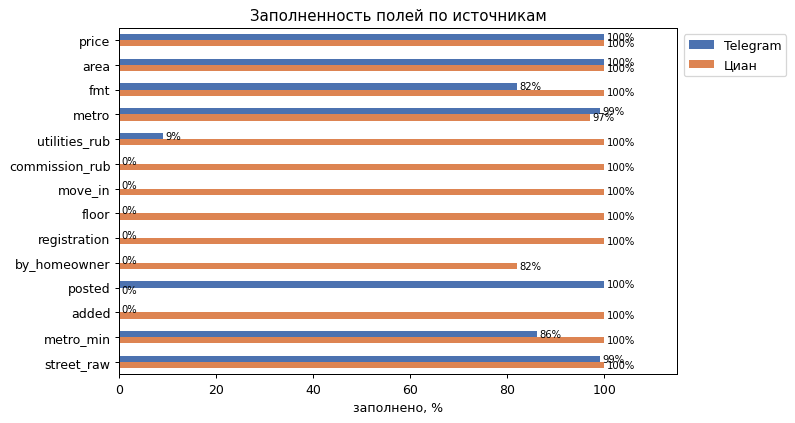

,"тг, % заполнено","циан, % заполнено"
price,100,100
area,100,100
fmt,82,100
metro,99,97
utilities_rub,9,100
commission_rub,0,100
move_in,0,100
floor,0,100
registration,0,100
by_homeowner,0,82


In [4]:
key_cols = ["price", "area", "fmt", "metro", "utilities_rub", "commission_rub", "move_in",
            "floor", "registration", "by_homeowner", "posted", "added", "metro_min", "street_raw"]
fill = (raw.groupby("source")[key_cols].apply(lambda g: g.notna().mean() * 100).T.round(0).astype(int))
fill.columns = [f"{c}, % заполнено" for c in fill.columns]

ax = fill.plot.barh(figsize=(8, 5), color=["#4C72B0", "#DD8452"])
ax.legend(["Telegram", "Циан"], loc="upper left", bbox_to_anchor=(1, 1))
ax.set_xlabel("заполнено, %")
ax.set_title("Заполненность полей по источникам")
ax.invert_yaxis()
ax.set_xlim(0, 115)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f%%", padding=2, fontsize=8)
plt.savefig(FIG / "fill_by_source.png", dpi=150, bbox_inches="tight")
fill

### 2.3. Что за объекты и на какой срок

In [5]:
display(pd.crosstab(raw["object"], raw["source"], margins=True, margins_name="всего"))
display(pd.crosstab(raw["lease"], raw["source"], margins=True, margins_name="всего"))
pd.crosstab(raw["fmt"].fillna("не указан"), raw["object"])

source,тг,циан,всего
object,,,
дом,2,0,2
квартира,854,285,1139
комната,190,0,190
всего,1046,285,1331


source,тг,циан,всего
lease,,,
длительно,750,143,893
коротко,296,0,296
несколько мес.,0,142,142
всего,1046,285,1331


object,дом,квартира,комната
fmt,,,
1-к,0,432,0
2-к,0,179,0
3-к,0,40,0
4-к,1,3,0
не указан,1,1,190
студия,0,484,0


### 2.4. Цена: распределение и выбросы

count      1331.0
mean      48175.0
std       26471.0
min        8500.0
1%        15000.0
25%       31000.0
50%       42000.0
75%       58000.0
99%      148500.0
max      350000.0

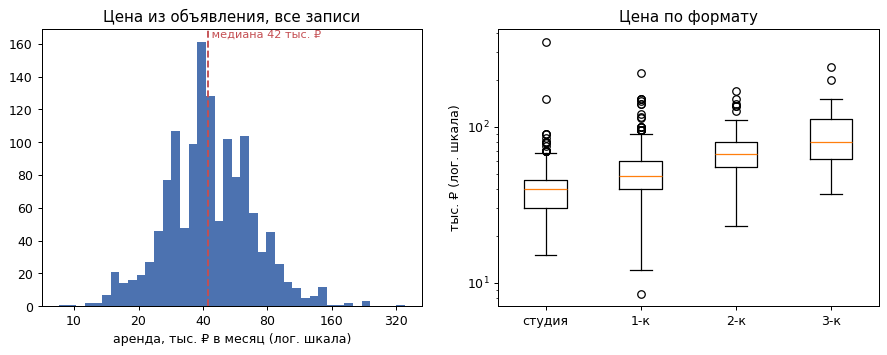

,source,object,fmt,area,price,lease
1235,тг,комната,NaN,250.0,18000.0,длительно
563,тг,комната,NaN,120.0,20000.0,длительно
461,тг,квартира,1-к,48.0,8500.0,коротко
962,тг,комната,NaN,100.0,30000.0,длительно
1049,тг,квартира,студия,20.4,70000.0,коротко
883,тг,квартира,студия,26.1,350000.0,длительно
940,тг,дом,4-к,NaN,50000.0,коротко
1084,тг,дом,NaN,NaN,130000.0,длительно


In [6]:
print(raw["price"].describe(percentiles=[.01, .25, .5, .75, .99]).round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(raw["price"]), bins=40, color="#4C72B0")
med_price = raw["price"].median()
axes[0].axvline(np.log10(med_price), color="#C44E52", linestyle="--", linewidth=1.5)
axes[0].text(np.log10(med_price), axes[0].get_ylim()[1], f" медиана {med_price / 1000:.0f} тыс. ₽",
             color="#C44E52", va="top", ha="left", fontsize=9)
axes[0].set_xticks(np.log10([10_000, 20_000, 40_000, 80_000, 160_000, 320_000]))
axes[0].set_xticklabels(["10", "20", "40", "80", "160", "320"])
axes[0].set_xlabel("аренда, тыс. ₽ в месяц (лог. шкала)")
axes[0].set_title("Цена из объявления, все записи")
order = ["студия", "1-к", "2-к", "3-к"]
axes[1].boxplot([raw.loc[raw["fmt"] == f, "price"] / 1000 for f in order], tick_labels=order, showfliers=True)
axes[1].set_yscale("log")
axes[1].set_ylabel("тыс. ₽ (лог. шкала)")
axes[1].set_title("Цена по формату")
plt.savefig(FIG / "price_raw.png", dpi=150, bbox_inches="tight")

raw.assign(price_m2=raw["price"] / raw["area"]).sort_values("price_m2")[
    ["source", "object", "fmt", "area", "price", "lease"]].iloc[np.r_[0:4, -4:0]]

### 2.5. Цена из объявления ≠ платёж

Полная цена считается только там, где известны коммуналка и комиссия, то есть по Циану:
`полная цена = аренда + коммуналка + комиссия / 11` (комиссия разовая, раскладываю её на 11 месяцев договора).
Считаю только долгую аренду: продукт для договора от 11 месяцев, а «комиссия / 11» к найму на
несколько месяцев неверна.

У коммуналки четыре статуса (`util_status`): `включена` в цену, указана `сумма`, `счётчики сверху`
(коммуналка включена, счётчики оплачиваются отдельно) и `не указано`. Парсер Циана записывал два последних
как 0 ₽, поэтому `total_month` из исходника — нижняя граница платежа: неизвестная коммуналка в ней равна нулю.
Главные цифры доплаты — на подготовленном наборе с оценкой коммуналки (раздел 3.7); здесь — только нижняя граница.

Циан, долгая аренда: 143 из 285 объявлений
  коммуналка не входит в цену (всё, кроме «включена»): 85%, из них сумма указана у 69% всех объявлений
  есть комиссия: 51%, медиана комиссии 24,800 ₽
  медианная доплата сверх цены (нижняя граница): 5,800 ₽ в месяц
  полная цена выше цены объявления больше чем на 10% (нижняя граница): 56%
Telegram: total_month совпадает с ценой у 100% записей — это не полная цена, а заглушка: полей коммуналки и комиссии в шаблоне нет
Telegram, коммуналка из текста поста: {'не указано': 822, 'счётчики сверху': 97, 'сумма': 95, 'включена': 32}

lease,длительно,несколько мес.,всего
util_status,,,
включена,22,47,69
не указано,13,10,23
сумма,99,73,172
счётчики сверху,9,12,21
всего,143,142,285


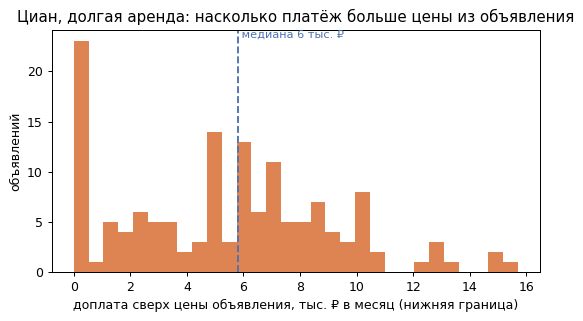

In [7]:
cian = raw[raw["source"] == "циан"]
display(pd.crosstab(cian["util_status"], cian["lease"], margins=True, margins_name="всего"))
cl = cian[cian["lease"] == "длительно"]
extra = cl["total_month"] - cl["price"]          # неизвестная коммуналка = 0: нижняя граница доплаты
share10 = (extra / cl["price"] > 0.10).mean()
fee = cl["commission_rub"] > 0
print(f"Циан, долгая аренда: {len(cl)} из {len(cian)} объявлений")
print(f"  коммуналка не входит в цену (всё, кроме «включена»): {cl['util_status'].ne('включена').mean():.0%}, "
      f"из них сумма указана у {cl['util_status'].eq('сумма').mean():.0%} всех объявлений")
print(f"  есть комиссия: {fee.mean():.0%}, медиана комиссии {cl.loc[fee, 'commission_rub'].median():,.0f} ₽")
print(f"  медианная доплата сверх цены (нижняя граница): {extra.median():,.0f} ₽ в месяц")
print(f"  полная цена выше цены объявления больше чем на 10% (нижняя граница): {share10:.0%}")
tg = raw[raw["source"] == "тг"]
print(f"Telegram: total_month совпадает с ценой у {(tg['total_month'] == tg['price']).mean():.0%} записей — "
      f"это не полная цена, а заглушка: полей коммуналки и комиссии в шаблоне нет")
print("Telegram, коммуналка из текста поста:", tg["util_status"].value_counts().to_dict())

ax = (extra / 1000).plot.hist(bins=30, figsize=(7, 3.5), color="#DD8452")
med_extra = extra.median() / 1000
ax.axvline(med_extra, color="#4C72B0", linestyle="--", linewidth=1.5)
ax.text(med_extra, ax.get_ylim()[1], f" медиана {med_extra:.0f} тыс. ₽",
        color="#4C72B0", va="top", ha="left", fontsize=9)
ax.set_xlabel("доплата сверх цены объявления, тыс. ₽ в месяц (нижняя граница)")
ax.set_ylabel("объявлений")
ax.set_title("Циан, долгая аренда: насколько платёж больше цены из объявления")
plt.savefig(FIG / "extra_cost.png", dpi=150, bbox_inches="tight")

### 2.6. Дорога: сколько объявлений рядом с метро и фитнес-клубом

Пример на типичной паре точек «метро + зал»: метро — любая станция, фитнес-клуб — любой сети.
В продукте точки выбирает пользователь, поэтому следом — та же доля для всех драйверов интереса.

Минуты точны, только если точка — дом (`geo = «дом»`: у Циана — точка из карточки, у Telegram — дом
нашёлся в адресах OSM). Если дом не нашёлся, точка стоит в центре улицы, а длинная улица — это
километры, то есть минуты — шум. Поэтому знаменатель всех долей «≤ 15 мин» — объявления с точкой
по дому, а объявления по центру улицы — отдельной строкой «приблизительно».

In [8]:
precise = raw["metro_min"].notna() & raw["geo"].eq("дом")
geo, approx = raw[precise], raw[raw["metro_min"].notna() & ~precise]
both = (geo["metro_min"] <= 15) & (geo["fitness_min"] <= 15)
print(f"Координаты есть у {raw['metro_min'].notna().sum()} из {len(raw)}: точка по дому — {len(geo)}, "
      f"по центру улицы — {len(approx)}")
print(f"Точка по дому, {len(geo)} объявлений:")
print(f"  ≤ 15 мин до метро (любой станции):     {(geo['metro_min'] <= 15).mean():.1%}")
print(f"  ≤ 15 мин до фитнес-клуба (любой сети): {(geo['fitness_min'] <= 15).mean():.1%}")
print(f"  ≤ 15 мин до обоих:                     {both.sum()} объявлений, {both.mean():.1%}")
print(f"Приблизительно (центр улицы), {len(approx)}: ≤ 15 мин до обоих — "
      f"{((approx['metro_min'] <= 15) & (approx['fitness_min'] <= 15)).mean():.1%}")

Координаты есть у 1188 из 1331: точка по дому — 945, по центру улицы — 243
Точка по дому, 945 объявлений:
  ≤ 15 мин до метро (любой станции):     65.7%
  ≤ 15 мин до фитнес-клуба (любой сети): 87.4%
  ≤ 15 мин до обоих:                     593 объявлений, 62.8%
Приблизительно (центр улицы), 243: ≤ 15 мин до обоих — 32.5%

In [9]:
near = pd.DataFrame({name: {"все, %": (geo[f"{k}_min"] <= 15).mean(),
                            "Telegram, %": (geo.loc[geo["source"] == "тг", f"{k}_min"] <= 15).mean(),
                            "Циан, %": (geo.loc[geo["source"] == "циан", f"{k}_min"] <= 15).mean(),
                            "приблизительно, %": (approx[f"{k}_min"] <= 15).mean()}
                     for k, name in DRIVERS.items()}).T
near.loc["ледовая арена с названием в OSM"] = [(geo["ice_named_min"] <= 15).mean(),
                                               (geo.loc[geo["source"] == "тг", "ice_named_min"] <= 15).mean(),
                                               (geo.loc[geo["source"] == "циан", "ice_named_min"] <= 15).mean(),
                                               (approx["ice_named_min"] <= 15).mean()]
near.index.name = f"≤ 15 мин пешком до (точка по дому: {len(geo)}, по центру улицы: {len(approx)})"
(near * 100).round(0).astype(int)

,"все, %","Telegram, %","Циан, %","приблизительно, %"
"≤ 15 мин пешком до (точка по дому: 945, по центру улицы: 243)",,,,
метро (любая станция),66,52,98,35
фитнес-клуб (любая сеть),87,82,100,70
детский сад,98,97,100,78
школа,97,96,100,89
поликлиника или больница,87,89,81,70
ледовая арена,17,20,10,15
стадион или спорткомплекс,89,84,100,65
парк,93,90,100,82
ледовая арена с названием в OSM,8,8,8,6


### 2.7. Покрытие по времени

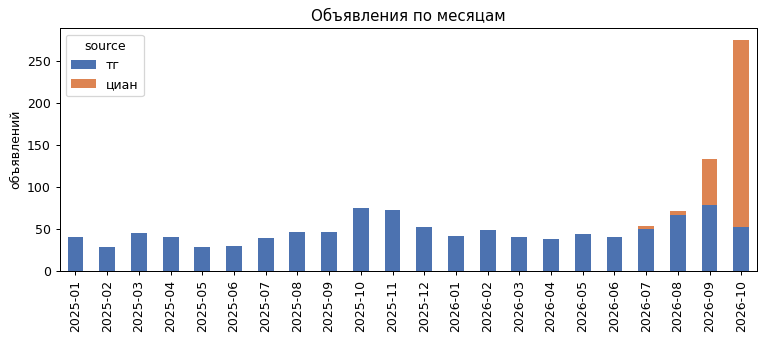

In [10]:
ym = raw.assign(ym=raw["year"].astype(str) + "-" + raw["month"].astype(str).str.zfill(2))
ax = pd.crosstab(ym["ym"], ym["source"]).plot.bar(stacked=True, figsize=(10, 3.5), color=["#4C72B0", "#DD8452"])
ax.set_xlabel("")
ax.set_ylabel("объявлений")
ax.set_title("Объявления по месяцам")
plt.savefig(FIG / "by_month.png", dpi=150, bbox_inches="tight")

### 2.8. Выводы по этапу 2

1. **Источники дополняют друг друга.** У Циана есть коммуналка, комиссия, этаж и сумма при въезде, но выборка узкая: одна выгрузка (июль – октябрь 2026, в основном октябрь), один район (три соседние станции), только студии и 1-к, и половина объявлений (142 из 285) — найм на несколько месяцев. Telegram даёт охват: весь город, 22 месяца, все форматы. Зато полей расходов в шаблоне поста нет: коммуналку удалось достать регулярками из текста только у 13% постов (сумма — у 9%), комиссию из текста я не разбирала.
2. **Боль подтверждается данными, и на долгой аренде она сильнее.** На подготовленном наборе Циана (140 объявлений долгой аренды, раздел 3.7) коммуналка не входит в цену у 84%, комиссия есть у 51% (медиана 23 900 ₽). С оценкой неизвестной коммуналки медианная доплата сверх цены из объявления — 6 000 ₽ в месяц, у 65% объявлений платёж выше цены больше чем на 10%. Нижняя граница — если считать только указанные в объявлении платежи: доплата не меньше 5 636 ₽, больше 10% — у 55%. В сыром наборе (раздел 2.5) видна только эта нижняя граница: у 22 объявлений коммуналка неизвестна, а парсер записал её как 0 ₽.
3. **В сыром наборе смешаны разные рынки и ошибки ввода.** 192 комнаты и дома, 438 объявлений не долгой аренды (296 посуточных и 142 «на несколько месяцев»). Цена — от 8,5 до 350 тыс. ₽, цена за м² — от 72 до 13 410 ₽, разница в 186 раз. Студия за 350 тыс. ₽ — явная опечатка.
4. **Половину отсекает метро, а не места человека.** Среди 945 объявлений с точкой по дому в 15 минутах пешком от метро — 66%, а от метро и фитнес-клуба сразу — 63%: зал почти ничего не добавляет к фильтру метро, который у площадок уже есть. Ценность ассистента — в местах, которых на площадках нет: ледовая арена в 15 минутах есть у 17% объявлений, а арена с названием в OSM — у 8%. Подробный водопад на подготовленном наборе — в разделе 3.6.
5. **Хватает ли данных.** Для базы карточек, полной цены по Циану, медиан цен по районам и расчёта минут пешком — да. Не хватает в четырёх местах: (а) расходов в Telegram-постах: регулярки нашли статус коммуналки у 13% постов, остальное — работа для языковой модели (этап 5), и её надо сравнить с регулярками на размеченных постах; (б) истории Циана: один месяц, сезонность по нему не видна; (в) координат: у 143 объявлений (11%) адрес не нашёлся, у 243 Telegram-объявлений точка — центр улицы, а не дом. Их минуты — шум, поэтому в долях «≤ 15 мин» они не участвуют и показаны отдельной строкой «приблизительно». Циан собран в одном районе, поэтому его доли по драйверам (98–100%) описывают этот район, а не город. Полнота OpenStreetMap не проверена: 395 фитнес-клубов и 58 ледовых объектов (у 40 нет названия) — это то, что разметили участники OSM, и пропущенный объект завышает минуты; (г) разметки мошенничества: правило «на 30% дешевле медианы» — эвристика, а не проверенная модель.

## Этап 3. Подготовка данных

### 3.1. Проблемы качества

Сначала считаю каждую проблему на исходном наборе, потом исправляю по одной и записываю в журнал,
сколько строк или значений изменилось.

In [11]:
def metro_key(name):
    """Ключ станции: регистр, ё, хвосты «1» и «#хештег» не важны."""
    s = str(name).split("#")[0].lower().replace("ё", "е")
    s = re.sub(r"\s+\d+$", "", s.strip())
    return re.sub(r"[^а-яa-z]+", "", s)



FIX = {"площадьленина": "Площадь Ленина", "площадьмужества": "Площадь Мужества",
       "площадьалександраневского": "Площадь Александра Невского", "проспектбольшевиков": "Проспект Большевиков",
       "проспектветеранов": "Проспект Ветеранов", "проспектпросвещения": "Проспект Просвещения",
       "улицадыбенко": "Улица Дыбенко", "чернаяречка": "Чёрная речка", "югозападная": "Юго-Западная"}
names = raw["metro"].str.split("#").str[0].str.replace(r"\s+\d+$", "", regex=True).str.strip()
canon = names.groupby(raw["metro"].map(metro_key)).agg(lambda s: s.value_counts().index[0] if s.notna().any() else np.nan)
canon.update(pd.Series(FIX))

issues = pd.DataFrame([
    ("Объекты вне задачи: комнаты и дома", (raw["object"] != "квартира").sum(),
     "строк"),
    ("Не долгая аренда: посуточно («коротко») и «несколько мес.»", (raw["lease"] != "длительно").sum(), "строк"),
    ("Повторы одного объявления (флаг парсера)", raw["is_dup_src"].sum(), "строк"),
    ("Станция метро записана с ошибкой (регистр, «1», «#хештег»)",
     (raw["metro"].map(metro_key).map(canon) != raw["metro"]).sum(), "значений"),
    ("Одна улица записана по-разному", raw["street_raw"].nunique() - raw["street_raw"].map(street_key).nunique(),
     "лишних вариантов"),
    ("Дата Циана текстом («вчера, 10:25», «14 окт»)", raw["added"].notna().sum(), "значений"),
    ("total_month в Telegram = цене (нет коммуналки и комиссии)",
     ((raw["source"] == "тг") & (raw["total_month"] == raw["price"])).sum(), "значений"),
    ("Коммуналка Циана неизвестна («не указано», «счётчики сверху»), а записана 0 ₽",
     ((raw["source"] == "циан") & raw["util_status"].isin(["не указано", "счётчики сверху"])
      & raw["utilities_rub"].eq(0)).sum(), "значений"),
    ("Невозможная цена за м²", 0, "строк, считается в шаге 6"),
    ("Нет координат (не нашёлся адрес)", (~raw["has_coords"]).sum(), "строк"),
    ("Координаты — центр улицы, а не дом: минуты приблизительные", (raw["geo"] == "улица").sum(), "строк"),
    ("Да/нет хранится как текст True/False с пропусками", raw[["registration", "by_homeowner"]].notna().sum().sum(),
     "значений"),
    ("«не указано» вместо пропуска в типе жилья", (raw["kind"] == "не указано").sum(), "значений"),
], columns=["проблема", "сколько", "ед."])
print("Полных дублей строк:", raw.drop(columns="offer_id").duplicated().sum())
issues

Полных дублей строк: 0

,проблема,сколько,ед.
0,Объекты вне задачи: комнаты и дома,192,строк
1,Не долгая аренда: посуточно («коротко») и «нес...,438,строк
2,Повторы одного объявления (флаг парсера),63,строк
3,"Станция метро записана с ошибкой (регистр, «1»...",132,значений
4,Одна улица записана по-разному,92,лишних вариантов
5,"Дата Циана текстом («вчера, 10:25», «14 окт»)",285,значений
6,total_month в Telegram = цене (нет коммуналки ...,1046,значений
7,"Коммуналка Циана неизвестна («не указано», «сч...",44,значений
8,Невозможная цена за м²,0,"строк, считается в шаге 6"
9,Нет координат (не нашёлся адрес),143,строк


### 3.2. Очистка по шагам

Каждый шаг — отдельная ячейка: что сделано и почему.

In [12]:
df = raw.copy()
LOG = []


def log(step, why, before, changed=None):
    LOG.append({"шаг": step, "строк до": before, "строк после": len(df),
                "изменено значений": changed, "зачем": why})

**Шаг 1. Оставляю только квартиры и апартаменты.** Комнаты и дома — другой рынок
с другими ценами: студия за 25 тыс. и комната за 25 тыс. несравнимы, а медианы цен по району,
на которых держится проверка «подозрительно дёшево», смешались бы.

In [13]:
n = len(df)
df = df[df["object"] == "квартира"].copy()
log("1. Только квартиры", "комнаты и дома — другой рынок, ломают медианы", n)
print(n, "→", len(df))

1331 → 1139

**Шаг 2. Оставляю только долгую аренду.** Продукт для тех, кто снимает от 11 месяцев. В постах «коротко»
цены за сутки, неделю и месяц перемешаны: 1-к за 8 500 и за 150 000 ₽ — это не рынок, а разные единицы.
«Несколько месяцев» с Циана тоже убираю: цена там месячная, но это другой продукт (часто апарт-отели),
и полная цена «аренда + коммуналка + комиссия / 11» к найму на 2–6 месяцев неверна: комиссия
раскладывается на срок договора, а он короче 11 месяцев.

In [14]:
n = len(df)
print("убираю:", df.loc[df["lease"] != "длительно"].groupby(["source", "lease"]).size().to_dict())
df = df[df["lease"] == "длительно"].copy()
log("2. Только долгая аренда", "продукт для аренды от 11 мес.; «коротко» — цены в разных единицах, "
    "«несколько мес.» — комиссия / 11 неверна", n)
print(n, "→", len(df))

убираю: {('тг', 'коротко'): 248, ('циан', 'несколько мес.'): 142}
1139 → 749

**Шаг 3. Привожу станции метро к одному написанию.** «Технологический институт 1»,
«Пушкинская #технологический институт», «Площадь ленина» — одна и та же станция должна
называться одинаково, иначе медиана по району считается по двум «разным» районам.
Каноническое имя — самое частое написание без хвостов, составные названия — по справочнику `FIX`.
Метки Циана («станция A») шаг не меняет.

In [15]:
before_names = df["metro"].nunique()
new_metro = df["metro"].map(metro_key).map(canon)
changed = (new_metro != df["metro"]).sum()
df["metro"] = new_metro
log("3. Единое написание станций", "одна станция — одно имя, иначе медианы по району дробятся", len(df), changed)
print(f"вариантов написания: {before_names} → {df['metro'].nunique()}, исправлено значений: {changed}")

вариантов написания: 91 → 90, исправлено значений: 97

**Шаг 4. Одна колонка даты публикации.** В Telegram дата есть (`posted`), у Циана — текст
«вчера, 10:25» или «14 окт, 12:36». Сбор Циана шёл 17.10.2026: в выгрузке есть и «вчера», и «15 окт»,
значит «вчера» — это 16.10 (если бы сбор был 16-го, Циан написал бы «вчера» вместо «15 окт»).

In [16]:
SCRAPE = pd.Timestamp("2026-10-17")
MON = {"янв": 1, "фев": 2, "мар": 3, "апр": 4, "мая": 5, "июн": 6,
       "июл": 7, "авг": 8, "сен": 9, "окт": 10, "ноя": 11, "дек": 12}


def cian_date(s):
    if pd.isna(s):
        return pd.NaT
    s = str(s).lower()
    if s.startswith("сегодня"):
        return SCRAPE
    if s.startswith("вчера"):
        return SCRAPE - pd.Timedelta(days=1)
    m = re.match(r"(\d{1,2})\s+([а-я]{3})", s)
    return pd.Timestamp(2026, MON[m[2]], int(m[1])) if m else pd.NaT


df["posted_date"] = pd.to_datetime(df["posted"]).fillna(df["added"].map(cian_date))
df["move_from"] = pd.to_datetime(df["move_from"])
log("4. Единая дата публикации", "у Циана дата текстом, у Telegram — датой", len(df), int(df["added"].notna().sum()))
print("без даты:", df["posted_date"].isna().sum())
df.groupby("source")["posted_date"].agg(["min", "max"])

без даты: 0

,min,max
source,,
тг,2025-01-03,2026-10-17
циан,2026-08-27,2026-10-16


**Шаг 5. Убираю повторы.** Одну квартиру выкладывают повторно, а иногда и в Telegram, и на Циане.
Ключ повтора: улица (нормализованная) + формат + площадь + цена + месяц публикации. Месяц нужен,
чтобы не склеить разные сдачи одной квартиры с разницей в год. Из повторов оставляю запись Циана
(в ней есть коммуналка и комиссия), иначе — самую раннюю. Для сверки — сколько повторов нашёл парсер
своим флагом `is_dup_src` (он видел полный адрес с домом).

In [17]:
df["street_key"] = df["street_raw"].map(street_key)
df["ym"] = df["posted_date"].dt.to_period("M")
dup_key = ["street_key", "fmt", "area", "price", "ym"]
df = df.sort_values(["source", "posted_date"], ascending=[False, True])   # «циан» раньше «тг»
has_street = df["street_key"].notna()
is_dup = df.duplicated(dup_key) & has_street
groups = df[df.duplicated(dup_key, keep=False) & has_street].groupby(dup_key, observed=True)["source"].nunique()
print(f"повторов по моему ключу: {is_dup.sum()}, из них одна квартира в Telegram и на Циане: {(groups > 1).sum()}")
print(f"флаг парсера: {df['is_dup_src'].sum()}, из них мой ключ тоже нашёл: {(is_dup & df['is_dup_src']).sum()}")
n = len(df)
df = df[~(is_dup | df["is_dup_src"])].copy()
log("5. Без повторов", "один объект — одна строка, иначе он «весит» вдвое в медианах и выдаче", n)
print(n, "→", len(df))

повторов по моему ключу: 14, из них одна квартира в Telegram и на Циане: 0
флаг парсера: 26, из них мой ключ тоже нашёл: 7
749 → 716

**Шаг 6. Выбросы цены.** Сравниваю не цену, а цену за м²: 200 тыс. за 4-к на 234 м² нормальны,
а 350 тыс. за студию 26 м² — явная ошибка ввода (видимо, 35 000). Границы считаю по
логарифму цены за м² (распределение скошено вправо):
за 3 межквартильных размаха — удаляю как невозможные, за 1,5 — оставляю, но помечаю `is_outlier`,
чтобы они не попадали в медианы района. Исправлять «на глаз» (350 000 → 35 000) не стану: это догадка.

In [18]:
df["price_m2"] = (df["price"] / df["area"]).round(0)
lg = np.log10(df["price_m2"])
q1, q3 = lg.quantile([.25, .75])
iqr = q3 - q1
hard = (lg < q1 - 3 * iqr) | (lg > q3 + 3 * iqr)
soft = (lg < q1 - 1.5 * iqr) | (lg > q3 + 1.5 * iqr)
print(f"границы ₽/м²: мягкие {10 ** (q1 - 1.5 * iqr):,.0f}–{10 ** (q3 + 1.5 * iqr):,.0f}, "
      f"жёсткие {10 ** (q1 - 3 * iqr):,.0f}–{10 ** (q3 + 3 * iqr):,.0f}")
display(df.loc[hard, ["source", "fmt", "area", "price", "price_m2", "metro"]])
n = len(df)
df = df[~hard].copy()
df["is_outlier"] = soft[~hard]
log("6. Невозможные цены за м²", "ошибки ввода искажают медианы и выдачу", n)
print(n, "→", len(df), f"; помечено is_outlier: {df['is_outlier'].sum()}")

границы ₽/м²: мягкие 597–3,088, жёсткие 322–5,720
716 → 715 ; помечено is_outlier: 5

,source,fmt,area,price,price_m2,metro
883,тг,студия,26.1,350000.0,13410.0,Проспект Ветеранов


**Шаг 7. Полная цена: честно разделяю «известно» и «оценка».** В Telegram `total_month` равнялся цене,
а у Циана неизвестная коммуналка была записана как 0 ₽. Для продукта это худшая ошибка: квартира
выглядит дешевле, чем есть. Поэтому:

- `utilities_rub` — только известная коммуналка: `включена` → честный 0, `сумма` → сумма;
  `счётчики сверху` и `не указано` → пусто, потому что «неизвестно» не равно нулю;
- `utilities_est` — оценка коммуналки: медиана указанных сумм для того же формата (студия / 1-к / 2-к / 3+),
  `utilities_lo`–`utilities_hi` — разброс p25–p75 той же группы; для `включена` и `сумма` оценка равна известному.
  Если у формата меньше 5 сумм, у 3+ берётся группа «2+» (2-к и 3+ вместе), у остальных — все форматы,
  а в `util_est_note` пишется «мало данных для формата»;
- `total_month_est` = аренда + `utilities_est` + комиссия / 11, `total_month_lo`–`total_month_hi` — диапазон.
  У Telegram комиссию в оценку не добавляю: канал «Уезжаю / Остаюсь» — в основном жильцы, которые
  передают квартиру, комиссии там обычно нет, а комиссия агентств с Циана завысила бы оценку;
- `total_month` — только известный платёж (Циан, коммуналка известна);
- `cost_basis` — откуда цифра: «известно», «оценка коммуналки» (`не указано`) или «оценка: счётчики»,
  чтобы ассистент писал «уточнить у хозяина».

In [19]:
cian_m = df["source"].eq("циан")
known = df["util_status"].isin(["включена", "сумма"])
changed = int((~known & df["utilities_rub"].eq(0)).sum())     # неизвестная коммуналка, записанная нулём
df["utilities_rub"] = df["utilities_rub"].where(known)
df.loc[df["util_status"].eq("включена"), "utilities_rub"] = 0

FMT_GROUP = {"студия": "студия", "1-к": "1-к", "2-к": "2-к", "3-к": "3+", "4-к": "3+"}
fmt_g = df["fmt"].map(FMT_GROUP)
sums = df.loc[df["util_status"].eq("сумма"), "utilities_rub"]
q = lambda p: (lambda s: s.quantile(p))                                   # noqa: E731
stats = lambda s: pd.Series({"n": len(s), "p25": s.quantile(.25), "median": s.median(), "p75": s.quantile(.75)})  # noqa: E731
MIN_N = 5                                                                 # меньше 5 сумм — медиана шире
util_stats = sums.groupby(fmt_g).apply(stats).unstack()
util_stats.loc["2+"] = stats(sums[fmt_g.isin(["2-к", "3+"])])           # 2-к и 3+ вместе
util_all = stats(sums)
src_of = {}                                                               # формат -> откуда оценка
for g in ["студия", "1-к", "2-к", "3+"]:
    n_g = util_stats["n"].get(g, 0)
    src_of[g] = (g if n_g >= MIN_N else "2+" if g == "3+" and util_stats.loc["2+", "n"] >= MIN_N else "все")
util_ref = util_stats.reindex(["студия", "1-к", "2-к", "3+", "2+"]).copy()
util_ref.loc["все"] = util_all
pick = lambda col: fmt_g.map({g: util_ref.loc[s, col] for g, s in src_of.items()}).fillna(util_all[col])  # noqa: E731

for col, stat in [("utilities_est", "median"), ("utilities_lo", "p25"), ("utilities_hi", "p75")]:
    df[col] = df["utilities_rub"].where(known, pick(stat))
# пометка: у формата мало своих сумм — оценка взята по группе «2+» или по всем форматам
df["util_est_note"] = np.where(~known & fmt_g.map(src_of).ne(fmt_g).fillna(True), "мало данных для формата", None)
fee = df["commission_rub"].fillna(0) / 11
for col, u in [("total_month_est", "utilities_est"), ("total_month_lo", "utilities_lo"), ("total_month_hi", "utilities_hi")]:
    df[col] = (df["price"] + df[u] + fee).round(0)
df["cost_basis"] = df["util_status"].map({"включена": "известно", "сумма": "известно",
                                          "не указано": "оценка коммуналки", "счётчики сверху": "оценка: счётчики"})
check = (df.loc[cian_m & known, "total_month_est"] - df.loc[cian_m & known, "total_month"]).abs()
print(f"проверка формулы на Циане (коммуналка известна): максимальное расхождение {check.max():.0f} ₽ (округление)")
df["total_month"] = df["total_month_est"].where(cian_m & known)
log("7. Полная цена: известно / оценка", "неизвестная коммуналка — не ноль; оценка медианой по формату, "
    "диапазон p25–p75", len(df), changed)
pd.crosstab(df["cost_basis"], df["source"], margins=True, margins_name="всего")

проверка формулы на Циане (коммуналка известна): максимальное расхождение 45 ₽ (округление)

source,тг,циан,всего
cost_basis,,,
известно,55,118,173
оценка коммуналки,460,13,473
оценка: счётчики,60,9,69
всего,575,140,715


**Коммуналка: статусы и оценка.** Таблицы ниже — сколько у каждого источника статусов коммуналки и из
каких сумм получилась оценка.

- **Почему медиана, а не среднее.** Суммы коммуналки скошены вправо: «зимой до 18 000», «10 000 + счётчики»
  рядом с типичными 4–6 тыс. Одно такое объявление сдвигает среднее на сотни рублей, а медиану почти не трогает.
  Разброс p25–p75 честнее одной цифры: ассистент показывает полную цену диапазоном.
- **Почему по формату.** В 2-к и 3-к больше людей и больше площадь, поэтому коммуналка выше. Общая медиана
  занизила бы платёж за 2-к и завысила за студию.
- **Почему не ₽/м².** Коммуналка не растёт пропорционально площади: в ней много постоянных платежей
  (интернет, домофон, вывоз мусора, капремонт и содержание по минимуму, вода и свет по числу жильцов).
  Если умножить «рубли за метр» студии на 70 м², получится переоценка; формат — грубее, но честнее.
- **Почему порог 5 сумм.** Медиана и квартили по 1–4 числам — это одно-два конкретных объявления, а не группа.
  При пяти суммах p25 и p75 уже держатся на разных объявлениях. Порог ниже прежних 10, потому что
  у 2-к своих сумм 5–9: общая медиана занижала бы их. У 3+ сумм почти нет, поэтому их оценка — по группе «2+»
  (2-к и 3+ вместе), а не по студиям, и строка помечена «мало данных для формата».

In [20]:
st = pd.crosstab(df["util_status"], df["source"], margins=True, margins_name="всего")
st_pct = (st / st.loc["всего"] * 100).round(0).astype(int)
display(st.astype(str) + " (" + st_pct.astype(str) + "%)")
tab = util_ref.rename(index={"2+": "2+ (2-к и 3+ вместе)", "все": "все форматы"})
NAMES = {"2+": "медиана группы «2+»", "все": "медиана всех форматов"}
tab["источник оценки"] = [("своя медиана" if src_of[g] == g else f"{NAMES[src_of[g]]} (мало данных: < {MIN_N} сумм)")
                          if g in src_of else "—" for g in util_ref.index]
tab["оценок по ней"] = [int((~known & fmt_g.eq(g)).sum()) if g in src_of else "—" for g in util_ref.index]
tab["n"] = tab["n"].fillna(0).astype(int)
tab[["p25", "median", "p75"]] = tab[["p25", "median", "p75"]].round(-2)
tab.index.name = "формат (долгая аренда, статус «сумма», оба источника)"
print("пометка «мало данных для формата»:", int(df["util_est_note"].notna().sum()), "строк")
tab

пометка «мало данных для формата»: 25 строк

source,тг,циан,всего
util_status,,,
включена,11 (2%),22 (16%),33 (5%)
не указано,460 (80%),13 (9%),473 (66%)
сумма,44 (8%),96 (69%),140 (20%)
счётчики сверху,60 (10%),9 (6%),69 (10%)
всего,575 (100%),140 (100%),715 (100%)


,n,p25,median,p75,источник оценки,оценок по ней
"формат (долгая аренда, статус «сумма», оба источника)",,,,,,
студия,71,4000.0,5000.0,6000.0,своя медиана,177
1-к,59,4000.0,5000.0,6800.0,своя медиана,226
2-к,8,5000.0,5500.0,7000.0,своя медиана,114
3+,1,18000.0,18000.0,18000.0,медиана группы «2+» (мало данных: < 5 сумм),25
2+ (2-к и 3+ вместе),9,5000.0,6000.0,7000.0,—,—
все форматы,140,4000.0,5000.0,6200.0,—,—


**Шаг 7б. Комиссия риэлтора по автору объявления.** Комиссия зависит от того, кто сдаёт, и её нельзя придумывать.
`author_role` — `собственник`, `риэлтор` или `неизвестно`: у Циана из поля `by_homeowner`, у Telegram — по словам
поста («на связи агент / собственник», «от собственника», «комиссия 50%»; «без комиссии» роль не доказывает).
Правило: собственник → комиссия 0 (честный ноль); риэлтор с названной комиссией → она; риэлтор без названной суммы →
оценка медианой рынка, диапазон p25–p75 (рынок — Циан, только риэлторы с комиссией > 0); автор неизвестен и комиссия
не названа → не придумываю: нижняя граница без комиссии, верхняя — с медианной комиссией, пометка «уточнить».
Комиссия разовая, поэтому в месячную цену она входит как `commission / 11` (как в шаге 7). Новые колонки:
`commission_est`, `commission_lo`, `commission_hi`, `commission_basis`, `total_month_auth_est`, `total_month_auth_lo`,
`total_month_auth_hi`; прежние `total_month_*` не менялись.

In [21]:
role = df["author_role"].fillna("неизвестно")
mk = cian_m & role.eq("риэлтор") & (df["commission_rub"] > 0)
mkt = df.loc[mk, "commission_rub"]
MKT = {"n": int(len(mkt)), "mean": mkt.mean(), "median": mkt.median(), "p25": mkt.quantile(.25), "p75": mkt.quantile(.75)}
print("рыночная комиссия (Циан, риэлторы с комиссией > 0): " + ", ".join(f"{k} {v:,.0f}" for k, v in MKT.items()))
stated = df["commission_rub"] > 0
est, lo, hi = (pd.Series(np.nan, index=df.index) for _ in range(3))
own, rea, unk = role.eq("собственник"), role.eq("риэлтор"), role.eq("неизвестно")
for m, (e, l, h) in [(stated & ~own, (df["commission_rub"],) * 3),             # названа сумма — берём её
                     (own, (0, 0, 0)),                                        # собственник — честный ноль
                     (rea & ~stated, (MKT["median"], MKT["p25"], MKT["p75"])),  # риэлтор без суммы — оценка рынка
                     (unk & ~stated, (np.nan, 0, MKT["median"]))]:            # автор неизвестен — «уточнить»
    est[m], lo[m], hi[m] = (v[m] if isinstance(v, pd.Series) else v for v in (e, l, h))
df["commission_est"], df["commission_lo"], df["commission_hi"] = est, lo, hi
df["commission_basis"] = np.select([own, stated, rea, unk], ["собственник: 0", "указана в объявлении",
                                   "оценка: средняя по рынку", "уточнить: автор неизвестен"], default="")
for col, u, c in [("est", "utilities_est", "commission_est"), ("lo", "utilities_lo", "commission_lo"),
                  ("hi", "utilities_hi", "commission_hi")]:
    df["total_month_auth_" + col] = (df["price"] + df[u] + df[c] / 11).round(0)
print("классы автора по источникам:")
display(pd.crosstab(df["author_role"].fillna("неизвестно"), df["source"], margins=True, margins_name="всего"))
print("в таблицах шага 3.7 Циан «неизвестно» с названной комиссией (> 0) показан как «вероятно риэлтор»: расчёт тот же, метка другая")
pd.crosstab(df["commission_basis"], df["source"], margins=True, margins_name="всего")

рыночная комиссия (Циан, риэлторы с комиссией > 0): n 48, mean 25,394, median 22,500, p25 16,375, p75 32,500
классы автора по источникам:
в таблицах шага 3.7 Циан «неизвестно» с названной комиссией (> 0) показан как «вероятно риэлтор»: расчёт тот же, метка другая

source,тг,циан,всего
author_role,,,
неизвестно,553,26,579
риэлтор,2,75,77
собственник,20,39,59
всего,575,140,715


source,тг,циан,всего
commission_basis,,,
оценка: средняя по рынку,2,27,29
собственник: 0,20,39,59
указана в объявлении,0,72,72
уточнить: автор неизвестен,553,2,555
всего,575,140,715


**Шаг 8. Типы.** Да/нет — в логический тип с пропусками (`boolean`): у Telegram этих полей нет,
и это «неизвестно», а не «нет». «не указано» в типе жилья — тоже пропуск.

In [22]:
for c in ["registration", "by_homeowner"]:
    df[c] = df[c].map({True: True, False: False, "True": True, "False": False}).astype("boolean")
changed = int((df["kind"] == "не указано").sum())
df["kind"] = df["kind"].replace("не указано", np.nan)
log("8. Типы данных", "да/нет — логический тип, «не указано» — пропуск", len(df), changed)
df[["registration", "by_homeowner", "kind"]].dtypes

registration    boolean
by_homeowner    boolean
kind             object
dtype: object

### 3.3. Преобразования под задачу

Данные идут не в обучение модели, а в правила и в контекст ассистента. Поэтому делаю только то,
что нужно правилам:

| Признак | Что это | Зачем |
|---|---|---|
| `rooms` | формат → число: студия 0, 1-к 1, … (Label Encoding) | порядок осмысленный: можно фильтровать «от 1-к и больше» |
| `is_tg`, `lease_long` | источник и срок → 0/1 | сравнение источников; после шага 2 `lease_long` везде 1, колонка оставлена для совместимости |
| `price_m2`, `median_m2_area` | цена за м² и её медиана по станции и формату (≥ 5 объявлений, иначе по формату; без `is_outlier`) | база для проверки «подозрительно дёшево»: по цене за м², иначе крошечные студии выглядят «подозрительно дешёвыми» |
| `price_vs_median` | отклонение цены за м² от медианы района | правило Проверяющего: на 30% дешевле — флаг |
| `walk_metro_15`, `walk_fitness_15` | ≤ 15 мин пешком до метро и до фитнес-клуба (пример; остальные `*_min` — по выбору пользователя) | жёсткий фильтр Калькулятора |
| `geo_precise` | точка — дом, а не центр улицы | минуты точны только у них; остальным ассистент пишет «приблизительно» |

Масштабирование не делаю: нет модели, чувствительной к масштабу (kNN, линейной регрессии),
а ассистенту нужны рубли и минуты в понятных единицах. One-hot для станций тоже не нужен:
станция — фильтр, а не вход модели.

In [23]:
df["rooms"] = df["fmt"].map({"студия": 0, "1-к": 1, "2-к": 2, "3-к": 3, "4-к": 4}).astype("Int64")
df["is_tg"] = df["source"].eq("тг").astype(int)
df["lease_long"] = df["lease"].eq("длительно").astype(int)

base = df[~df["is_outlier"]]
by_area = base.groupby(["metro", "fmt"])["price_m2"].agg(["median", "size"])
by_fmt = base.groupby("fmt")["price_m2"].median()
med = df.join(by_area, on=["metro", "fmt"])
df["median_m2_area"] = np.where(med["size"] >= 5, med["median"], df["fmt"].map(by_fmt))
df["price_vs_median"] = (df["price_m2"] / df["median_m2_area"] - 1).round(3)
df["flag_cheap"] = df["price_vs_median"] <= -0.30
df["walk_metro_15"] = (df["metro_min"] <= 15).astype("boolean").where(df["metro_min"].notna())
df["walk_fitness_15"] = (df["fitness_min"] <= 15).astype("boolean").where(df["fitness_min"].notna())
df["geo_precise"] = df["metro_min"].notna() & df["geo"].eq("дом")      # центр улицы — минуты приблизительные
log("9. Преобразования", "кодирование формата и срока, медианы района, флаги «дёшево» и «≤ 15 мин»", len(df))
print(f"«подозрительно дёшево» (≥ 30% ниже медианы района): {df['flag_cheap'].sum()} объявлений")
df.loc[df["flag_cheap"], ["source", "metro", "fmt", "area", "price", "price_m2", "median_m2_area", "price_vs_median"]].head(8)

«подозрительно дёшево» (≥ 30% ниже медианы района): 45 объявлений

,source,metro,fmt,area,price,price_m2,median_m2_area,price_vs_median
101,циан,станция S,студия,29.0,40000.0,1379.0,2111.0,-0.347
193,циан,станция C,1-к,56.0,45000.0,804.0,1316.0,-0.389
95,циан,станция S,студия,30.0,37000.0,1233.0,2111.0,-0.416
61,циан,станция R,1-к,35.0,32000.0,914.0,1316.0,-0.305
133,циан,станция E,студия,32.0,37000.0,1156.0,1916.5,-0.397
98,циан,станция N,1-к,44.9,38000.0,846.0,1316.0,-0.357
285,тг,Новочеркасская,3-к,89.0,60000.0,674.0,1067.0,-0.368
317,тг,Новочеркасская,3-к,94.4,60000.0,636.0,1067.0,-0.404


### 3.4. Итоговый набор и сохранение

In [24]:
KEEP = ["offer_id", "source", "is_tg", "posted_date", "year", "month", "move_from",
        "metro", "street_key", "has_coords", "geo", "geo_precise", "metro_min", "fitness_min", "kindergarten_min",
        "school_min", "clinic_min", "ice_min", "ice_named_min", "sport_min", "park_min",
        "walk_metro_15", "walk_fitness_15",
        "kind", "fmt", "rooms", "area", "floor", "floors",
        "lease", "lease_long", "registration", "by_homeowner",
        "price", "price_m2", "util_status", "utilities_rub", "utilities_est", "utilities_lo", "utilities_hi",
        "commission_rub", "total_month", "total_month_est", "total_month_lo", "total_month_hi",
        "cost_basis", "util_est_note", "author_role", "commission_est", "commission_lo", "commission_hi",
        "commission_basis", "total_month_auth_est", "total_month_auth_lo", "total_month_auth_hi", "move_in", "median_m2_area", "price_vs_median", "flag_cheap", "is_outlier"]
clean = df[KEEP].sort_values("offer_id").reset_index(drop=True)
clean.to_csv(DATA / "offers_clean.csv", index=False)
log_df = pd.DataFrame(LOG)
log_df.to_csv(DATA / "cleaning_log.csv", index=False)
print(f"offers_clean.csv: {clean.shape[0]} строк × {clean.shape[1]} признаков")
log_df

offers_clean.csv: 715 строк × 60 признаков

,шаг,строк до,строк после,изменено значений,зачем
0,1. Только квартиры,1331,1139,NaN,"комнаты и дома — другой рынок, ломают медианы"
1,2. Только долгая аренда,1139,749,NaN,продукт для аренды от 11 мес.; «коротко» — цен...
2,3. Единое написание станций,749,749,97.0,"одна станция — одно имя, иначе медианы по райо..."
3,4. Единая дата публикации,749,749,143.0,"у Циана дата текстом, у Telegram — датой"
4,5. Без повторов,749,716,NaN,"один объект — одна строка, иначе он «весит» вд..."
5,6. Невозможные цены за м²,716,715,NaN,ошибки ввода искажают медианы и выдачу
6,7. Полная цена: известно / оценка,715,715,22.0,неизвестная коммуналка — не ноль; оценка медиа...
7,8. Типы данных,715,715,17.0,"да/нет — логический тип, «не указано» — пропуск"
8,9. Преобразования,715,715,NaN,"кодирование формата и срока, медианы района, ф..."


### 3.5. Сравнение «до / после»

In [25]:
def profile(d, clean_view):
    tg_fake = ((d["source"] == "тг") & (d["total_month"] == d["price"])).sum()
    return {
        "строк": len(d),
        "признаков": d.shape[1],
        "комнаты, дома, не долгая аренда": int(((d.get("object", "квартира") != "квартира")
                                                 | (d["lease"] != "длительно")).sum()),
        "повторы (флаг парсера)": int(d["is_dup_src"].sum()) if "is_dup_src" in d else 0,
        "вариантов написания метро": d["metro"].nunique(),
        "цена: медиана, ₽": int(d["price"].median()),
        "цена: максимум, ₽": int(d["price"].max()),
        "₽/м²: максимум": int((d["price"] / d["area"]).max()),
        "total_month заполнен, %": round(d["total_month"].notna().mean() * 100),
        "  из них настоящий платёж, %": round((d["total_month"].notna().sum() - tg_fake) / len(d) * 100),
        "оценка платежа помечена, %": round((d.get("cost_basis") != "известно").mean() * 100) if clean_view else 0,
        "коммуналка 0 ₽, хотя неизвестна": int((d["util_status"].isin(["не указано", "счётчики сверху"])
                                                 & d["utilities_rub"].eq(0)).sum()),
        "дата публикации датой, %": round((d["posted_date"].notna().mean() if "posted_date" in d else d["posted"].notna().mean()) * 100),
    }


cmp = pd.DataFrame({"исходный": profile(raw, False), "подготовленный": profile(clean, True)})
cmp

,исходный,подготовленный
строк,1331,715
признаков,38,60
"комнаты, дома, не долгая аренда",582,0
повторы (флаг парсера),63,0
вариантов написания метро,95,90
"цена: медиана, ₽",42000,45000
"цена: максимум, ₽",350000,220000
₽/м²: максимум,13409,3400
"total_month заполнен, %",100,17
"из них настоящий платёж, %",21,17


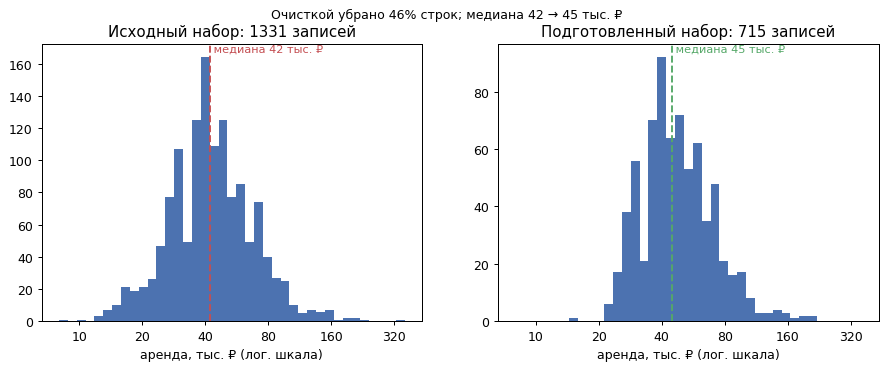

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
bins = np.linspace(np.log10(8_000), np.log10(360_000), 40)
med_raw, med_clean = raw["price"].median(), clean["price"].median()
for ax, d, t, med, mcolor in [(axes[0], raw, "Исходный набор", med_raw, "#C44E52"),
                               (axes[1], clean, "Подготовленный набор", med_clean, "#55A868")]:
    ax.hist(np.log10(d["price"]), bins=bins, color="#4C72B0")
    ax.axvline(np.log10(med), color=mcolor, linestyle="--", linewidth=1.5)
    ax.text(np.log10(med), ax.get_ylim()[1], f" медиана {med / 1000:.0f} тыс. ₽",
            color=mcolor, va="top", ha="left", fontsize=9)
    ax.set_xticks(np.log10([10_000, 20_000, 40_000, 80_000, 160_000, 320_000]))
    ax.set_xticklabels(["10", "20", "40", "80", "160", "320"])
    ax.set_xlabel("аренда, тыс. ₽ (лог. шкала)")
    ax.set_title(f"{t}: {len(d)} записей")
removed_pct = 1 - len(clean) / len(raw)
fig.suptitle(f"Очисткой убрано {removed_pct:.0%} строк; медиана {med_raw / 1000:.0f} → {med_clean / 1000:.0f} тыс. ₽",
             fontsize=10)
plt.savefig(FIG / "before_after.png", dpi=150, bbox_inches="tight")

### 3.6. Водопад: сколько вариантов остаётся после каждого условия

Площадки уже умеют фильтровать по метро, поэтому ценность ассистента — не в фильтре «≤ 15 минут до метро»,
а в том, что он добавляет к нему: места, важные конкретному человеку. Считаю на подготовленном наборе
последовательно: все → есть координаты → точка по дому (`geo_precise`) → ≤ 15 мин до метро → плюс
фитнес-клуб → плюс детский сад и поликлиника → плюс каток. Каток в двух версиях: все объекты `ice`
из OSM и только с названием (безымянные точки бывают дворовыми заливками). Порог — 15 минут пешком
для всех объектов.

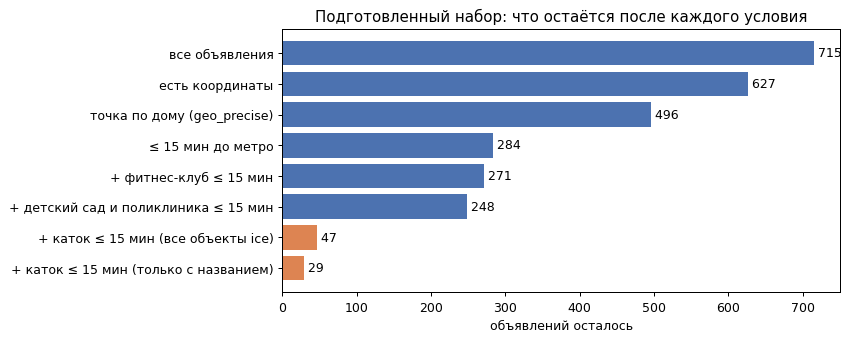

,осталось,было на шаге,% от всех,"отсеяно шагом, %",% от фильтра метро
условие,,,,,
все объявления,715,715,100.0,0.0,NaN
есть координаты,627,715,87.7,12.3,NaN
точка по дому (geo_precise),496,627,69.4,20.9,NaN
≤ 15 мин до метро,284,496,39.7,42.7,100.0
+ фитнес-клуб ≤ 15 мин,271,284,37.9,4.6,95.4
+ детский сад и поликлиника ≤ 15 мин,248,271,34.7,8.5,87.3
+ каток ≤ 15 мин (все объекты ice),47,248,6.6,81.0,16.5
+ каток ≤ 15 мин (только с названием),29,248,4.1,88.3,10.2


In [27]:
steps = [("все объявления", pd.Series(True, index=clean.index)),
         ("есть координаты", clean["metro_min"].notna()),
         ("точка по дому (geo_precise)", clean["geo_precise"]),
         ("≤ 15 мин до метро", clean["metro_min"] <= 15),
         ("+ фитнес-клуб ≤ 15 мин", clean["fitness_min"] <= 15),
         ("+ детский сад и поликлиника ≤ 15 мин", (clean["kindergarten_min"] <= 15) & (clean["clinic_min"] <= 15))]
mask, rows = pd.Series(True, index=clean.index), []
for name, cond in steps:
    prev = mask.sum()
    mask = mask & cond.fillna(False).astype(bool)
    rows.append((name, mask.sum(), prev))
for name, col in [("+ каток ≤ 15 мин (все объекты ice)", "ice_min"),
                  ("+ каток ≤ 15 мин (только с названием)", "ice_named_min")]:
    rows.append((name, (mask & (clean[col] <= 15).fillna(False).astype(bool)).sum(), mask.sum()))
fall = pd.DataFrame(rows, columns=["условие", "осталось", "было на шаге"]).set_index("условие")
fall["% от всех"] = (fall["осталось"] / len(clean) * 100).round(1)
fall["отсеяно шагом, %"] = ((1 - fall["осталось"] / fall["было на шаге"]) * 100).round(1)
base_metro = fall.loc["≤ 15 мин до метро", "осталось"]
fall["% от фильтра метро"] = (fall["осталось"] / base_metro * 100).round(1).where(
    fall.index.get_loc("≤ 15 мин до метро") <= np.arange(len(fall)))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(fall.index[::-1], fall["осталось"][::-1], color=["#DD8452"] * 2 + ["#4C72B0"] * (len(fall) - 2))
for i, v in enumerate(fall["осталось"][::-1]):
    ax.text(v, i, f" {v}", va="center")
ax.set_xlabel("объявлений осталось")
ax.set_title("Подготовленный набор: что остаётся после каждого условия")
fall

### 3.7. Метрика ценности: цена объявления против полной цены

Если ассистент считает полную цену, а площадка сортирует по цене объявления, то пользователь видит
разные «самые дешёвые» варианты. Проверяю на Циане (долгая аренда — только у него есть комиссия
и коммуналка): какая доля десятки самых дешёвых по цене объявления выпадает из десятки самых дешёвых
по `total_month_est`, и насколько вообще совпадают два порядка (тау Кендалла: 1 — порядок тот же,
0 — не связан). Для неизвестной коммуналки беру оценку, поэтому пересчитываю и по краям диапазона.

In [28]:
c = clean[clean["source"] == "циан"]
top_ad = set(c.sort_values(["price", "offer_id"]).head(10)["offer_id"])
value = {}
for col in ["total_month_est", "total_month_lo", "total_month_hi"]:
    top_full = set(c.sort_values([col, "offer_id"]).head(10)["offer_id"])
    value[col] = {"выпало из топ-10, %": len(top_ad - top_full) * 10,
                  "тау Кендалла": round(c["price"].corr(c[col], method="kendall"), 2)}
print(f"Циан, долгая аренда: {len(c)} объявлений")
display(pd.DataFrame(value).T)
c.sort_values(["price", "offer_id"]).head(10).assign(
    в_топ10_по_полной=lambda d: d["offer_id"].isin(set(c.sort_values(["total_month_est", "offer_id"]).head(10)["offer_id"])))[
    ["offer_id", "fmt", "price", "util_status", "commission_rub", "total_month_est", "cost_basis", "в_топ10_по_полной"]]

Циан, долгая аренда: 140 объявлений

,"выпало из топ-10, %",тау Кендалла
total_month_est,20.0,0.89
total_month_lo,20.0,0.88
total_month_hi,20.0,0.88


,offer_id,fmt,price,util_status,commission_rub,total_month_est,cost_basis,в_топ10_по_полной
1,4,студия,24990.0,счётчики сверху,12495.0,31126.0,оценка: счётчики,True
0,2,студия,26000.0,включена,0.0,26000.0,известно,True
2,6,студия,26000.0,включена,13000.0,27182.0,известно,True
6,24,студия,28000.0,сумма,14000.0,32773.0,известно,True
12,39,студия,29000.0,сумма,0.0,35000.0,известно,False
5,22,студия,29999.0,сумма,0.0,32499.0,известно,True
3,12,1-к,30000.0,включена,0.0,30000.0,известно,True
4,15,студия,30000.0,включена,0.0,30000.0,известно,True
9,36,студия,30000.0,сумма,15000.0,34364.0,известно,True
13,42,студия,30000.0,сумма,15000.0,35864.0,известно,False


**Доплата сверх цены объявления на подготовленном наборе.** Две версии на тех же объявлениях Циана:
главная — с оценкой неизвестной коммуналки (`total_month_est − price`), и нижняя граница — только платежи,
указанные в объявлении (коммуналка `сумма` + комиссия / 11, неизвестная коммуналка = 0). Эти же числа
уходят в `data/dashboard_data.json` (блок `extra_cost`), из него их берут отчёт и дашборд.

In [29]:
extra_est = c["total_month_est"] - c["price"]                                       # с оценкой коммуналки
extra_known = c["utilities_rub"].fillna(0) + c["commission_rub"].fillna(0) / 11     # только указанные платежи
has_fee = c["commission_rub"] > 0
pay = {"n": len(c), "est_median": extra_est.median(), "est_over10": (extra_est / c["price"] > 0.10).mean(),
       "known_median": extra_known.median(), "known_over10": (extra_known / c["price"] > 0.10).mean(),
       "commission_share": has_fee.mean(), "commission_median": c.loc[has_fee, "commission_rub"].median(),
       "util_not_included": c["util_status"].ne("включена").mean()}
print(f"Циан, долгая аренда, подготовленный набор: {pay['n']} объявлений")
print(f"  коммуналка не входит в цену: {pay['util_not_included']:.0%}; комиссия есть у {pay['commission_share']:.0%}, "
      f"медиана комиссии {pay['commission_median']:,.0f} ₽")
pd.DataFrame({"медианная доплата, ₽ в месяц": [extra_est.median(), extra_known.median()],
              "платёж выше цены > 10%, %": [pay["est_over10"] * 100, pay["known_over10"] * 100]},
             index=["с оценкой коммуналки (главная цифра)", "только указанные платежи (нижняя граница)"]).round(0)

Циан, долгая аренда, подготовленный набор: 140 объявлений
  коммуналка не входит в цену: 84%; комиссия есть у 51%, медиана комиссии 23,900 ₽

,"медианная доплата, ₽ в месяц","платёж выше цены > 10%, %"
с оценкой коммуналки (главная цифра),6000.0,65.0
только указанные платежи (нижняя граница),5636.0,55.0


**Доплата по автору объявления.** Те же объявления, три класса: у собственника комиссии нет, у риэлтора она названа
или оценена медианой рынка, у неизвестного автора — диапазон «без комиссии … с медианной комиссией» (уточнить).
`lo` / `est` / `hi` — нижняя граница, оценка и верхняя граница полной цены (`total_month_auth_*`); «боль» — доля
объявлений, где полная цена выше цены объявления больше чем на 10%. Для неизвестного автора оценки `est` нет.

In [30]:
def author_label(d):
    # Циан, автор неизвестен, но комиссия названа (> 0) — «вероятно риэлтор» (расчёт тот же); колонка author_role не меняется
    role = d["author_role"].fillna("неизвестно")
    return role.mask(role.eq("неизвестно") & d["source"].eq("циан") & (d["commission_rub"] > 0), "вероятно риэлтор")


def author_table(d):
    out = {}
    lab = author_label(d)
    for cls in ["собственник", "риэлтор", "вероятно риэлтор", "неизвестно", "все"]:
        g = d if cls == "все" else d[lab.eq(cls)]
        row = {"n": len(g)}
        for k in ("lo", "est", "hi"):
            t = g["total_month_auth_" + k]
            row["полная, медиана, ₽ (" + k + ")"] = t.median()
            row["боль > 10%, % (" + k + ")"] = ((t - g["price"]) / g["price"]).dropna().gt(.10).mean() * 100
        out[cls] = row
    return pd.DataFrame(out).T
author_cost = {"market_commission": {k: float(v) for k, v in MKT.items()}}
for src_, name in [("циан", "Циан"), ("тг", "Telegram")]:
    tab = author_table(clean[clean["source"] == src_])
    author_cost[name] = tab.round(1).replace({np.nan: None}).to_dict("index")
    print(name + ":")
    display(tab.round(1))
author_cost["cian_unknown_with_commission"] = int(author_label(clean).eq("вероятно риэлтор").sum())   # «вероятно риэлтор»
author_cost["cian_realtor_commission_zero"] = int(((clean["source"] == "циан") & clean["author_role"].eq("риэлтор")
                                                   & ~(clean["commission_rub"] > 0)).sum())
print("Циан, автор неизвестен, но комиссия названа:", author_cost["cian_unknown_with_commission"],
      "| риэлтор без названной комиссии:", author_cost["cian_realtor_commission_zero"])

Циан:
Telegram:
Циан, автор неизвестен, но комиссия названа: 24 | риэлтор без названной комиссии: 27

,n,"полная, медиана, ₽ (lo)","боль > 10%, % (lo)","полная, медиана, ₽ (est)","боль > 10%, % (est)","полная, медиана, ₽ (hi)","боль > 10%, % (hi)"
собственник,39.0,56000.0,35.9,56000.0,41.0,56000.0,53.8
риэлтор,75.0,47045.0,76.0,47045.0,77.3,47955.0,80.0
вероятно риэлтор,24.0,52659.0,87.5,52659.0,87.5,52659.0,91.7
неизвестно,2.0,53000.0,50.0,NaN,NaN,55045.0,50.0
все,140.0,50909.0,66.4,50636.5,68.8,51609.5,74.3


,n,"полная, медиана, ₽ (lo)","боль > 10%, % (lo)","полная, медиана, ₽ (est)","боль > 10%, % (est)","полная, медиана, ₽ (hi)","боль > 10%, % (hi)"
собственник,20.0,49000.0,35.0,50000.0,70.0,51750.0,80.0
риэлтор,2.0,44489.0,100.0,46045.0,100.0,48330.0,100.0
вероятно риэлтор,0.0,NaN,NaN,NaN,NaN,NaN,NaN
неизвестно,553.0,51000.0,32.7,NaN,NaN,55045.0,91.1
все,575.0,50000.0,33.0,50000.0,72.7,54045.0,90.8


### 3.8. Поток объявлений: сколько новых вариантов в месяц и сколько подходит человеку

Для экономики и дашборда нужен не запас, а поток: сколько новых объявлений долгой аренды квартир приходит
в месяц и сколько из них подходит конкретному человеку. Профили — три типичных набора мест, все на точке
по дому (`geo_precise`), порог 15 минут пешком: «метро + фитнес», «метро + садик + поликлиника»,
«метро + каток с названием в OSM». Telegram — по месяцам публикации (канал по всему городу); неполные
месяцы на краях выгрузки в медиану не идут. Циан собран один раз (17.10.2026), в одном районе и только
студии и 1-к, поэтому у него не поток по месяцам, а «сколько опубликовано за 30 дней до сбора».

In [31]:
PROFILES = {"метро + фитнес": ["metro_min", "fitness_min"],
            "метро + садик + поликлиника": ["metro_min", "kindergarten_min", "clinic_min"],
            "метро + каток с названием": ["metro_min", "ice_named_min"]}
fl = pd.DataFrame({"все": True, "точка по дому": clean["geo_precise"].astype(bool)}, index=clean.index)
for name, cols in PROFILES.items():
    fl[name] = fl["точка по дому"] & (clean[cols] <= 15).all(axis=1)
fl["ym"] = clean["posted_date"].dt.to_period("M")

tg_m = clean["source"].eq("тг")
months = pd.period_range(fl.loc[tg_m, "ym"].min(), fl.loc[tg_m, "ym"].max(), freq="M")
flow_month = fl[tg_m].groupby("ym").sum().reindex(months, fill_value=0).astype(int)
first, last = clean.loc[tg_m, "posted_date"].min(), clean.loc[tg_m, "posted_date"].max()
partial = [p for p, d in ((months[0], first), (months[-1], last))
           if (p == months[0] and d.day > 3) or (p == months[-1] and d.day < p.days_in_month - 3)]
full = flow_month.drop(index=partial)

cian_l = clean["source"].eq("циан")
SCRAPE_DAY = pd.Timestamp("2026-10-17")
c30 = cian_l & clean["posted_date"].between(SCRAPE_DAY - pd.Timedelta(days=30), SCRAPE_DAY)
cols = ["все", "точка по дому", *PROFILES]
flow_summary = pd.DataFrame({
    f"Telegram: медиана в месяц ({len(full)} полных мес.)": full[cols].median(),
    "Telegram: меньше всего за месяц": full[cols].min(),
    "Telegram: больше всего за месяц": full[cols].max(),
    "Циан: опубликовано за 30 дней до сбора": fl.loc[c30, cols].sum(),
    f"Циан: всего собрано ({clean.loc[cian_l, 'posted_date'].min():%d.%m}–{SCRAPE_DAY:%d.%m.%Y})": fl.loc[cian_l, cols].sum(),
}).T
print(f"Telegram: {months[0]} – {months[-1]}, неполные месяцы (не в медиане): {[str(p) for p in partial] or 'нет'}")
display(flow_summary.round(1))
flow_month.index = flow_month.index.astype(str)
flow_month.T

Telegram: 2025-01 – 2026-10, неполные месяцы (не в медиане): ['2026-10']

,все,точка по дому,метро + фитнес,метро + садик + поликлиника,метро + каток с названием
Telegram: медиана в месяц (21 полных мес.),23.0,13.0,6.0,6.0,0.0
Telegram: меньше всего за месяц,12.0,6.0,0.0,0.0,0.0
Telegram: больше всего за месяц,48.0,30.0,15.0,15.0,3.0
Циан: опубликовано за 30 дней до сбора,137.0,137.0,132.0,116.0,15.0
Циан: всего собрано (27.08–17.10.2026),140.0,140.0,135.0,117.0,15.0


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
все,18,12,21,23,13,21,25,26,22,43,30,22,24,32,23,23,22,20,31,47,48,29
точка по дому,13,6,13,14,6,13,13,20,13,29,24,16,17,19,12,13,13,11,18,26,30,17
метро + фитнес,8,3,4,6,0,4,6,10,4,7,7,6,3,4,6,6,4,3,6,15,14,10
метро + садик + поликлиника,7,3,6,5,0,4,6,10,5,9,8,7,3,5,6,6,4,3,6,15,15,10
метро + каток с названием,0,0,2,0,0,1,0,0,0,1,1,0,0,0,0,0,1,0,1,3,3,3


### 3.9. Почему подготовленный набор лучше подходит задаче

- **Один рынок вместо трёх.** Остались только квартиры и апартаменты в долгую аренду, поэтому медианы по району сравнимы. Медиана цены выросла с 42 до 45 тыс. ₽: дешёвые комнаты её занижали. Найм Циана «на несколько месяцев» (142 объявления) тоже убран: «комиссия / 11» к нему неверна.
- **Каждая квартира — одна строка.** Удалено 33 повтора: 14 нашёл мой ключ «улица + формат + площадь + цена + месяц», остальные — флаг парсера, который видел полный адрес. Совпадений между Telegram и Цианом не нашлось. Похоже, это разные аудитории: собственники и жильцы против агентств.
- **Полная цена больше не врёт.** В сыром наборе `total_month` был заполнен на 100%, но у 79% строк это была цена без коммуналки и комиссии, а у 44 строк Циана неизвестная коммуналка стояла нулём. Теперь у коммуналки четыре статуса: `включена` (честный 0), `сумма`, `счётчики сверху` и `не указано`. Платёж известен у 24% строк, у 66% коммуналка оценена (`cost_basis = «оценка коммуналки»`, о коммуналке ни слова), у 10% — «оценка: счётчики» (платится сверху, сумма не названа: «+КУ», «по счётчикам»). Оценка — медиана указанных сумм по формату, если у формата их не меньше 5: 5 000 ₽ для студий и 1-к (разброс p25–p75 4 000–6 000 и 4 000–6 800 ₽), 5 500 ₽ для 2-к (5 000–7 000 ₽, 8 сумм); у 3+ сумма одна, поэтому оценка — по группе «2+» (2-к и 3+ вместе): 6 000 ₽ (5 000–7 000 ₽), такие строки помечены «мало данных для формата». Полная цена показывается диапазоном `total_month_lo`–`total_month_hi`.
- **Минуты честные.** `geo_precise` отделяет точку по дому (496 строк) от центра улицы (131 строка Telegram): доли «≤ 15 мин» считаются только по первым.
- **Фильтры работают.** Станция записана одинаково (было 95 вариантов написания, стало 90: 67 станций Telegram и 23 метки станций Циана), дата публикации есть у 100% строк. Значит, работают фильтры «у метро X» и «свежее 14 дней».
- **Готовые поля для правил.** `rooms`, минуты до восьми драйверов интереса (`metro_min`, `fitness_min` и т. д.) и каток в двух версиях (`ice_min`, `ice_named_min`), `walk_metro_15`, `walk_fitness_15`, `util_status`, `utilities_est`, `total_month_lo`–`total_month_hi`, `median_m2_area`, `price_vs_median`, `flag_cheap` — это прямые входы для Калькулятора и Проверяющего из этапа 4.
- **Что добавляет ассистент к площадке.** Водопад (3.6): из 715 строк у 496 точка по дому, у метро — 284. Фитнес-клуб убирает из них ещё 5%, детский сад и поликлиника — ещё 9%, а каток — 81% (с названием — 88%): тому, кто ходит на хоккей, подходит 47 вариантов из 284 у метро, а с названием катка — 29. Сортировка по полной цене тоже меняет выбор (3.7): из десятки самых дешёвых по цене объявления на Циане две выпадают из десятки по полной цене, при общем согласии порядков (тау Кендалла 0,89).

**Чем заплатили:** из 1 331 строки осталось 715 (54%). Почти все удалённые — вне задачи: комнаты, дома, посуточная и краткосрочная аренда. У Циана осталось 140 строк из 285. Если продукт расширится на комнаты или короткий найм, их надо вернуть отдельным сегментом со своими медианами и своей формулой полной цены. Станции Циана обезличены метками, поэтому их медианы ₽/м² считаются отдельно от Telegram; флаг «дёшево» стоит у 45 объявлений (39 Telegram, 6 Циан). Оценка платежа для Telegram не включает комиссию: в канале обычно сдают жильцы, а не агентства. Это допущение, как и оценка коммуналки для «счётчики сверху» полной медианой (там часть коммуналки уже в цене, так что оценка скорее завышена); проверять — разметкой текстов постов (этап 5).